# Standalone 1-File Kaggle Submission — Final 3-Seed Tuned LightGBM

**100% Self-Contained:** Requires zero external `.py` or `.json` files — upload this single `.ipynb` directly to Kaggle!  
**Model:** 3-Seed Bagged Optuna-Tuned LightGBM (`seeds = [42, 2024, 2026]`, Stratified 5-Fold CV = 15 models averaged) on the 34 verified selected features (dropping universal `gain == 0` feature `is_brand_new_card`).  
**Validated OOF AUPRC:** `0.514561` | **Output:** `/kaggle/working/submission.csv` (on Kaggle) or `submission_lgbm_final.csv` (locally).

---
## Section 1: Imports, Auto-Path Detection & Standalone Pipeline

In [1]:
import os
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

LOCAL_SUBMISSION_PATH = "submission_lgbm_final.csv"
RETRAIN_IF_LOCAL_NPY_EXISTS = False  # Always trains automatically on Kaggle where .npy files are absent
SEEDS = [42, 2024, 2026]

def resolve_data_paths() -> tuple[str, str, str, str]:
    """Auto-detect Kaggle competition input directory or fall back to local workspace."""
    is_kaggle = os.path.exists("/kaggle/input")
    if is_kaggle:
        found = {}
        for root, _, files in os.walk("/kaggle/input"):
            for fname in ("train.csv", "test.csv", "sample_submission.csv"):
                if fname in files and fname not in found:
                    found[fname] = os.path.join(root, fname)
        if len(found) == 3:
            return found["train.csv"], found["test.csv"], found["sample_submission.csv"], "/kaggle/working/submission.csv"
        raise FileNotFoundError(f"Missing competition CSVs under /kaggle/input. Found: {found}")
    base = "." if os.path.exists("train.csv") else ".."
    return (
        os.path.join(base, "train.csv"),
        os.path.join(base, "test.csv"),
        os.path.join(base, "sample_submission.csv"),
        LOCAL_SUBMISSION_PATH,
    )

SEED = 42
N_SPLITS = 5
ID_COL = "id"
TARGET_COL = "is_fraud"

CONT_COLS = [
    "amount_usd", "hours_since_last_txn", "txn_count_last_24h",
    "distance_from_home_km", "card_age_months", "customer_age",
    "account_balance_usd", "cvv_retry_count", "velocity_score",
    "merchant_risk_score", "prior_disputes",
]
TIME_COLS = ["time_of_day_hour", "day_of_week"]
CAT_COLS = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
RISK_FLAG_COLS = [
    "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt",
]
ENGINEERED_COLS = [
    "amount_to_balance_ratio", "is_over_balance", "amount_per_txn_24h",
    "travel_speed_kmh", "is_brand_new_card", "has_cvv_retry",
    "hour_sin", "hour_cos", "is_night_txn", "is_weekend", "total_risk_flags",
]


def evaluate_auprc(y_true, y_pred_proba) -> float:
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_pred_proba, dtype=np.float64)
    if np.isnan(y_prob_arr).any() or np.isinf(y_prob_arr).any():
        raise ValueError("Predicted probabilities contain NaN or Inf values.")
    return float(average_precision_score(y_true_arr, y_prob_arr))


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Deterministic row-level feature engineering (zero data leakage)."""
    out = df.copy()
    for flag_col in RISK_FLAG_COLS:
        out[flag_col] = out[flag_col].astype(float if out[flag_col].isnull().any() else int)

    out["amount_to_balance_ratio"] = out["amount_usd"] / (out["account_balance_usd"] + 1e-5)
    out["is_over_balance"] = (out["amount_usd"] > out["account_balance_usd"]).astype(int)
    out["amount_per_txn_24h"] = out["amount_usd"] / (out["txn_count_last_24h"] + 1)
    out["travel_speed_kmh"] = out["distance_from_home_km"] / (out["hours_since_last_txn"] + 0.1)
    out["is_brand_new_card"] = (out["card_age_months"] <= 1).astype(int)
    out["has_cvv_retry"] = (out["cvv_retry_count"] > 0).astype(int)
    out["hour_sin"] = np.sin(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["hour_cos"] = np.cos(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["is_night_txn"] = out["time_of_day_hour"].between(0, 5).astype(int)

    dow = out["day_of_week"]
    if pd.api.types.is_numeric_dtype(dow):
        dow_valid = dow.dropna()
        if len(dow_valid) > 0 and dow_valid.min() >= 1 and dow_valid.max() == 7:
            out["is_weekend"] = dow.isin([6, 7]).astype(int)
        else:
            out["is_weekend"] = dow.isin([5, 6]).astype(int)
    else:
        weekend_strings = {"saturday", "sunday", "sat", "sun"}
        out["is_weekend"] = dow.astype(str).str.strip().str.lower().isin(weekend_strings).astype(int)

    out["total_risk_flags"] = out[RISK_FLAG_COLS].sum(axis=1)
    return out

# Verified 34 selected features (drops universal gain == 0 feature: is_brand_new_card)
SELECTED_FEATURES_34 = [
    c for c in (CONT_COLS + TIME_COLS + CAT_COLS + RISK_FLAG_COLS + ENGINEERED_COLS)
    if c != "is_brand_new_card"
]

# Optuna-tuned LightGBM hyperparameters (Trial #29)
BEST_LGBM_PARAMS = {
    "objective": "binary",
    "metric": "average_precision",
    "boosting_type": "gbdt",
    "learning_rate": 0.028804556398208715,
    "n_estimators": 4000,
    "num_leaves": 11,
    "max_depth": 4,
    "colsample_bytree": 0.4615970860753574,
    "subsample": 0.9581351083206087,
    "subsample_freq": 1,
    "min_child_samples": 172,
    "reg_alpha": 0.3089016400296857,
    "reg_lambda": 18.30744086412154,
    "scale_pos_weight": 3.359272372588889,
    "n_jobs": -1,
    "verbose": -1,
}

TRAIN_PATH, TEST_PATH, SAMPLE_SUB_PATH, SUBMISSION_PATH = resolve_data_paths()
print(f"Train CSV      : {TRAIN_PATH}")
print(f"Test CSV       : {TEST_PATH}")
print(f"Sample Sub CSV : {SAMPLE_SUB_PATH}")
print(f"Submission Out : {SUBMISSION_PATH}")
print(f"Features       : {len(SELECTED_FEATURES_34)} selected features | Seeds: {SEEDS}")

Train CSV      : train.csv
Test CSV       : test.csv
Sample Sub CSV : sample_submission.csv
Submission Out : submission_lgbm_final.csv
Features       : 34 selected features | Seeds: [42, 2024, 2026]


---
## Section 2: Load Data, Feature Engineering & 3-Seed 5-Fold LightGBM Training

In [2]:
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)
use_precomputed = (
    not RETRAIN_IF_LOCAL_NPY_EXISTS
    and not os.path.exists("/kaggle/input")
    and os.path.exists("oof_lgbm.npy")
    and os.path.exists("test_lgbm.npy")
)

if use_precomputed:
    print("Local pre-computed oof_lgbm.npy and test_lgbm.npy detected — reloading directly...")
    train_targets = pd.read_csv(TRAIN_PATH, usecols=[TARGET_COL])[TARGET_COL].astype(np.int64).to_numpy()
    oof_preds = np.load("oof_lgbm.npy").astype(np.float64)
    test_preds = np.load("test_lgbm.npy").astype(np.float64)
else:
    t0 = time.perf_counter()
    train_df = build_features(pd.read_csv(TRAIN_PATH))
    test_df = build_features(pd.read_csv(TEST_PATH))
    train_df[TARGET_COL] = train_df[TARGET_COL].astype(int)

    # Synchronize categorical dtypes across train and test
    for col in CAT_COLS:
        cats = sorted(pd.concat([train_df[col], test_df[col]], ignore_index=True).dropna().astype(str).unique())
        cat_dtype = pd.CategoricalDtype(categories=cats, ordered=False)
        train_df[col] = train_df[col].where(train_df[col].notna(), None).astype(cat_dtype)
        test_df[col] = test_df[col].where(test_df[col].notna(), None).astype(cat_dtype)

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    train_targets = train_df[TARGET_COL].to_numpy(dtype=np.int64)
    X_all = train_df[SELECTED_FEATURES_34]
    X_test = test_df[SELECTED_FEATURES_34]

    oof_preds = np.zeros(len(train_df), dtype=np.float64)
    test_preds = np.zeros(len(test_df), dtype=np.float64)
    fold_auprcs = []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_all, train_targets)):
        X_tr, y_tr = X_all.iloc[tr_idx], train_targets[tr_idx]
        X_va, y_va = X_all.iloc[va_idx], train_targets[va_idx]

        fold_val = np.zeros(len(va_idx), dtype=np.float64)
        fold_test = np.zeros(len(test_df), dtype=np.float64)
        iters = []

        for seed in SEEDS:
            params = dict(BEST_LGBM_PARAMS)
            params["random_state"] = int(seed)
            params["bagging_seed"] = int(seed)
            params["feature_fraction_seed"] = int(seed)

            model = lgb.LGBMClassifier(**params)
            model.fit(
                X_tr, y_tr,
                eval_set=[(X_va, y_va)],
                eval_metric="average_precision",
                categorical_feature=CAT_COLS,
                callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
            )
            best_iter = int(model.best_iteration_ or params["n_estimators"])
            iters.append(best_iter)
            fold_val += model.predict_proba(X_va, num_iteration=best_iter)[:, 1] / len(SEEDS)
            fold_test += model.predict_proba(X_test, num_iteration=best_iter)[:, 1] / len(SEEDS)

        oof_preds[va_idx] = fold_val
        test_preds += fold_test / N_SPLITS
        f_auprc = evaluate_auprc(y_va, fold_val)
        fold_auprcs.append(f_auprc)
        print(f"Fold {fold} | Val AUPRC: {f_auprc:.6f} | Best Iters: {iters}")

    np.save("oof_lgbm.npy", oof_preds)
    np.save("test_lgbm.npy", test_preds)
    print(f"\nMean 5-Fold AUPRC: {np.mean(fold_auprcs):.6f} +/- {np.std(fold_auprcs):.6f} | Elapsed: {time.perf_counter()-t0:.1f}s")

oof_auprc = evaluate_auprc(train_targets, oof_preds)
oof_roc = float(roc_auc_score(train_targets, oof_preds))
prec, rec, ths = precision_recall_curve(train_targets, oof_preds)
f1s = np.divide(2.0 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
best_idx = int(np.argmax(f1s))
best_th = float(ths[best_idx]) if best_idx < len(ths) else 0.5
print(f"OOF AUPRC: {oof_auprc:.6f} | OOF ROC-AUC: {oof_roc:.6f} | Best F1: {f1s[best_idx]:.6f} @ th={best_th:.4f}")

Local pre-computed oof_lgbm.npy and test_lgbm.npy detected — reloading directly...


OOF AUPRC: 0.514561 | OOF ROC-AUC: 0.947308 | Best F1: 0.505128 @ th=0.5202


---
## Section 3: Diagnostics & Export Validated Kaggle Submission

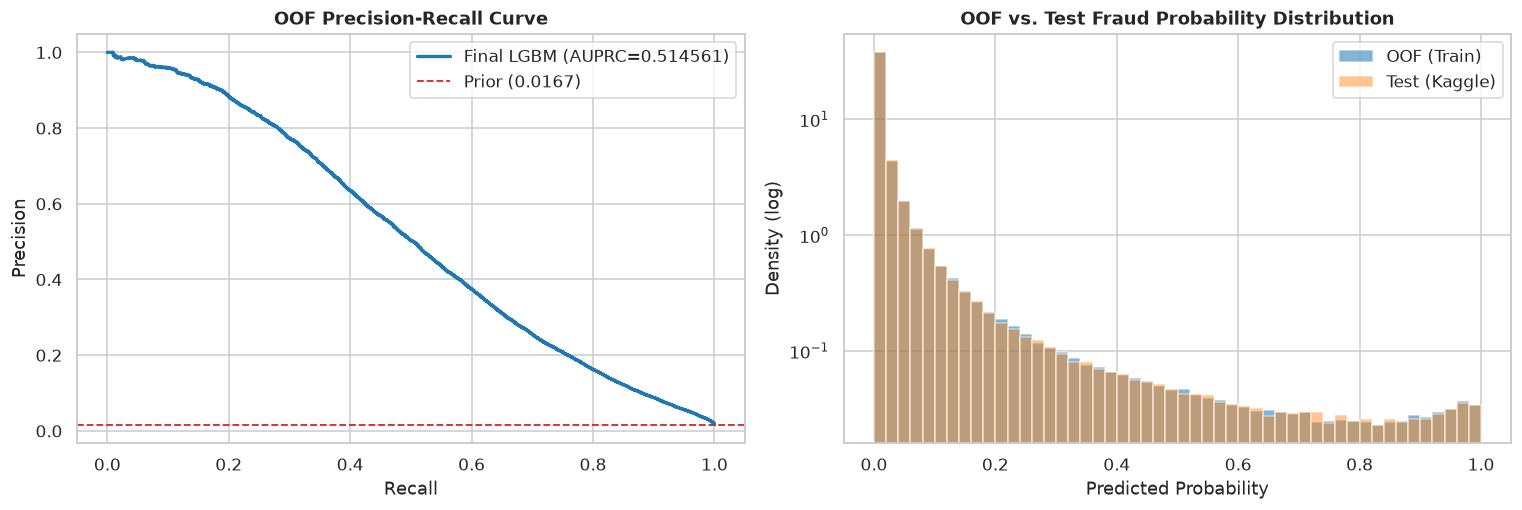

ALL KAGGLE SUBMISSION CHECKS PASSED -> /home/slimebuck/Documents/School/Code/Machine Learning/Predicting Credit Card Fraud/submission_lgbm_final.csv (8.43 MB)


,id,is_fraud
0,699960,0.000621
1,699961,0.000285
2,699962,0.247096
3,699963,0.004294
4,699964,0.002603
5,699965,0.000594
6,699966,0.016185
7,699967,0.001269
8,699968,0.019103
9,699969,0.001745


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(rec, prec, color="#1f77b4", lw=2.2, label=f"Final LGBM (AUPRC={oof_auprc:.6f})")
axes[0].axhline(train_targets.mean(), color="#d62728", ls="--", lw=1.2, label=f"Prior ({train_targets.mean():.4f})")
axes[0].set_title("OOF Precision-Recall Curve", fontweight="bold")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].legend()

bins = np.linspace(0.0, 1.0, 51)
axes[1].hist(oof_preds, bins=bins, density=True, alpha=0.55, color="#1f77b4", label="OOF (Train)")
axes[1].hist(test_preds, bins=bins, density=True, alpha=0.45, color="#ff7f0e", label="Test (Kaggle)")
axes[1].set_yscale("log")
axes[1].set_title("OOF vs. Test Fraud Probability Distribution", fontweight="bold")
axes[1].set_xlabel("Predicted Probability"); axes[1].set_ylabel("Density (log)"); axes[1].legend()
plt.tight_layout(); plt.show()

submission = pd.DataFrame({ID_COL: sample_sub[ID_COL].astype(np.int64), TARGET_COL: test_preds.astype(np.float64)})
submission.to_csv(SUBMISSION_PATH, index=False)

sub_check = pd.read_csv(SUBMISSION_PATH)
assert sub_check.shape == sample_sub.shape, f"Shape mismatch: {sub_check.shape} != {sample_sub.shape}"
assert list(sub_check.columns) == list(sample_sub.columns), f"Columns mismatch: {list(sub_check.columns)}"
assert np.array_equal(sub_check[ID_COL].to_numpy(), sample_sub[ID_COL].to_numpy()), "ID order mismatch!"
assert sub_check[TARGET_COL].isna().sum() == 0 and np.isfinite(sub_check[TARGET_COL].to_numpy()).all(), "NaN/Inf detected!"
assert (sub_check[TARGET_COL] >= 0.0).all() and (sub_check[TARGET_COL] <= 1.0).all(), "Probabilities out of [0, 1]!"
assert sub_check[TARGET_COL].std() > 1e-4, "Predictions appear constant!"

print(f"ALL KAGGLE SUBMISSION CHECKS PASSED -> {os.path.abspath(SUBMISSION_PATH)} ({os.path.getsize(SUBMISSION_PATH)/1e6:.2f} MB)")
display(sub_check.head(10))